# Data cleaning with ThreeWToolkit

This notebook demonstrates `CleanSignals`, `ImputeMissing`, `FillLabels`, and `RemapClass`. It also shows how to combine preprocessing with `SequentialPreprocessingAdapterConfig` and feature extractors with `ConcatFeatureAdapterConfig`.

In [20]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from ThreeWToolkit.dataset import ParquetDatasetConfig, TransformConfig
from ThreeWToolkit.feature_extraction import *
from ThreeWToolkit.preprocessing import *

DATASET_PATH = Path("../../dataset")
CLASSES = [1, 2, 3]
MAX_PER_CLASS = 5
files = [
    path
    for event_class in CLASSES
    for path in sorted(
        (DATASET_PATH / str(event_class)).glob("SIMULATED_*.parquet")
    )[:MAX_PER_CLASS]
]
dataset = ParquetDatasetConfig(
    path=DATASET_PATH,
    split="list",
    file_list=[str(path.relative_to(DATASET_PATH)) for path in files],
    target_class=CLASSES,
    event_type=["simulated"],
).build()
print(f"Loaded {len(dataset)} events")

2026-10-16 15:09:07,744 | INFO | ThreeWToolkit.dataset.parquet_dataset | Dataset found at ../../dataset
2026-10-16 15:09:07,745 | INFO | ThreeWToolkit.dataset.parquet_dataset | Validating dataset integrity...
2026-10-16 15:09:07,747 | INFO | ThreeWToolkit.dataset.parquet_dataset | Dataset integrity check passed!


Loaded 15 events


## Inspect the raw event

A dataset item contains a signal `DataFrame`, labels, and metadata. Missing sensor values are normal in the raw data because sensors are not present in every event.

In [21]:
raw_event = dataset[0]
print("Signal shape:", raw_event.signal.shape)
print("Metadata:", raw_event.metadata)
display(raw_event.signal.isna().sum().sort_values(ascending=False).head(10))
display(raw_event.signal.head())

Signal shape: (45599, 28)
Metadata: {'file_name': PosixPath('1/SIMULATED_00001.parquet'), 'event_class': 1, 'event_type': 'simulated'}


ABER-CKGL        45599
ABER-CKP         45599
ESTADO-DHSV      45599
ESTADO-M1        45599
ESTADO-M2        45599
ESTADO-PXO       45599
ESTADO-SDV-GL    45599
ESTADO-SDV-P     45599
ESTADO-W1        45599
ESTADO-W2        45599
dtype: int64

,ABER-CKGL,ABER-CKP,ESTADO-DHSV,ESTADO-M1,ESTADO-M2,ESTADO-PXO,ESTADO-SDV-GL,ESTADO-SDV-P,ESTADO-W1,ESTADO-W2,...,P-PDG,PT-P,P-TPT,QBS,QGL,T-JUS-CKP,T-MON-CKP,T-PDG,T-TPT,state
timestamp,,,,,,,,,,,,,,,,,,,,,
2018-10-06 03:57:02,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,2.252041e+07,NaN,1.306863e+07,NaN,NaN,70.334018,NaN,NaN,96.93275,0
2018-10-06 03:57:03,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,2.252043e+07,NaN,1.306865e+07,NaN,NaN,70.334248,NaN,NaN,96.93279,0
2018-10-06 03:57:04,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,2.252044e+07,NaN,1.306864e+07,NaN,NaN,70.334488,NaN,NaN,96.93283,0
2018-10-06 03:57:05,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,2.252042e+07,NaN,1.306860e+07,NaN,NaN,70.334728,NaN,NaN,96.93287,0
2018-10-06 03:57:06,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,2.252039e+07,NaN,1.306856e+07,NaN,NaN,70.334958,NaN,NaN,96.93290,0


## Explore missingness across events

A single event only shows part of the data-quality picture. The following summary counts available values for every signal across the selected events, making columns that are never observed easy to identify.

In [22]:
averages, counts = [], []
for event in dataset:
    averages.append(event.signal.mean())
    counts.append(event.signal.count())

total_counts = sum(counts)
missing_columns = total_counts[total_counts == 0].index
print("Signals with no observations:", list(missing_columns))
display(total_counts.sort_values().head(10))

Signals with no observations: ['ABER-CKGL', 'ABER-CKP', 'ESTADO-DHSV', 'ESTADO-M1', 'ESTADO-M2', 'ESTADO-PXO', 'ESTADO-SDV-GL', 'ESTADO-SDV-P', 'ESTADO-W1', 'ESTADO-W2', 'ESTADO-XO', 'P-ANULAR', 'P-JUS-BS', 'P-JUS-CKGL', 'P-JUS-CKP', 'P-MON-CKGL', 'P-MON-SDV-P', 'PT-P', 'QBS', 'QGL', 'T-MON-CKP', 'T-PDG']


ABER-CKGL        0
ABER-CKP         0
ESTADO-DHSV      0
ESTADO-M1        0
ESTADO-M2        0
ESTADO-PXO       0
ESTADO-SDV-GL    0
ESTADO-SDV-P     0
ESTADO-W1        0
ESTADO-W2        0
dtype: int64

The distribution of event-level means can also reveal suspicious readings, such as negative values or measurements concentrated at a sensor limit.

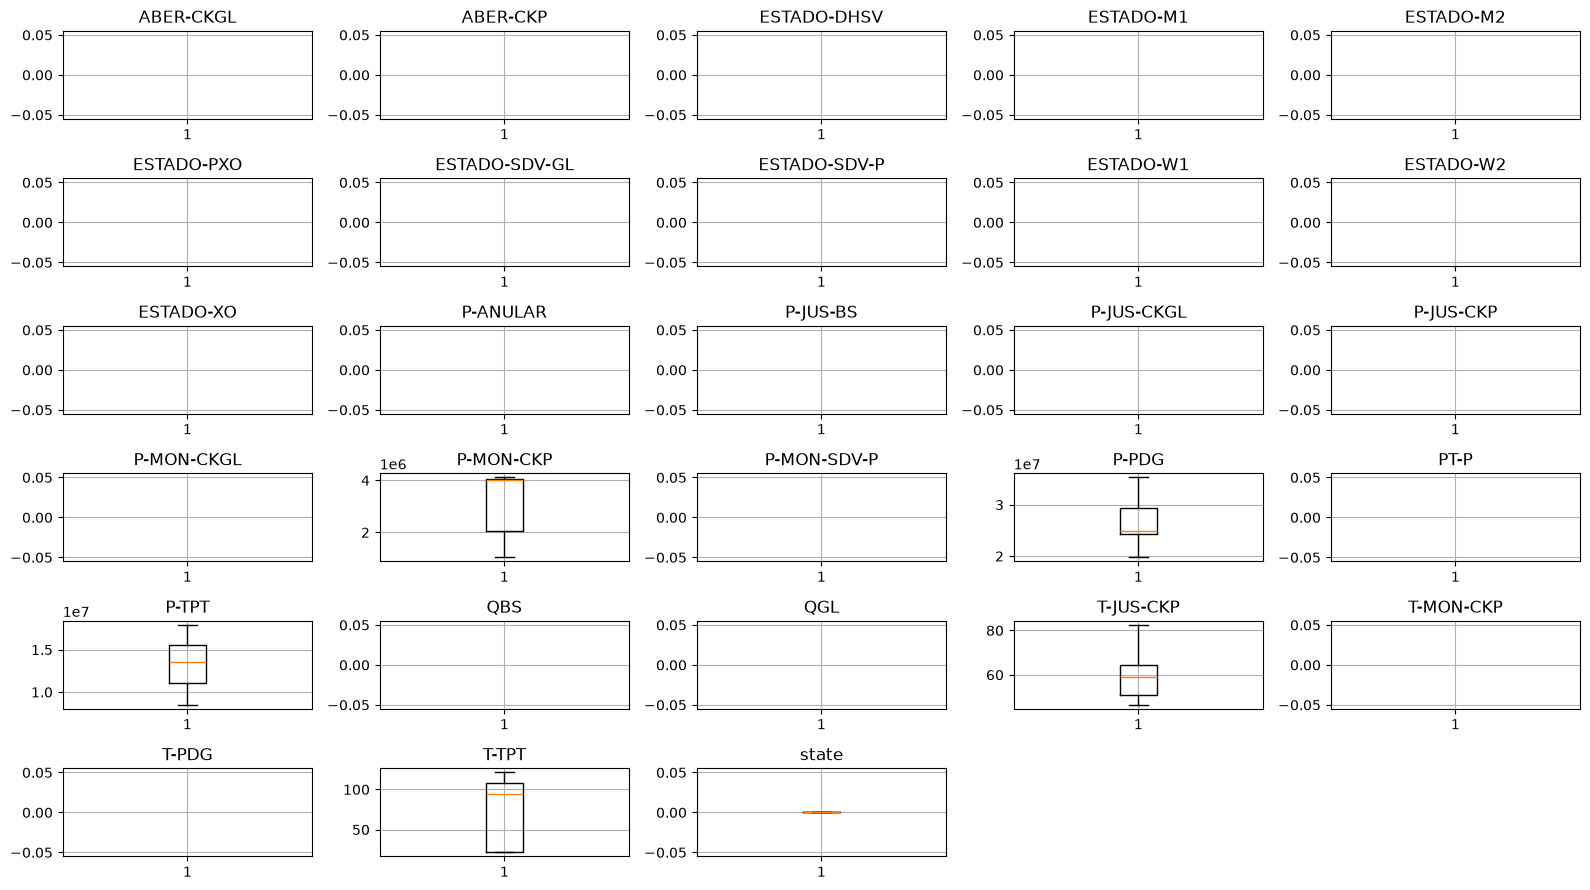

In [23]:
signals = total_counts.index
distribution = {
    signal: [
        average[signal]
        for average, count in zip(averages, counts)
        if count.get(signal, 0) != 0
    ]
    for signal in signals
}

n_rows = int(np.ceil(np.sqrt(len(distribution))))
n_cols = int(np.ceil(len(distribution) / n_rows))
_, axes = plt.subplots(n_rows, n_cols, figsize=(16, 9), tight_layout=True)
axes = np.atleast_1d(axes).ravel()
for axis, (signal, values) in zip(axes, distribution.items()):
    axis.boxplot(values)
    axis.set_title(signal)
    axis.grid()
for axis in axes[len(distribution):]:
    axis.remove()
plt.show()

## Clean suspicious readings

`CleanSignals` fits IQR-based bounds across events. Continuous readings outside those bounds are replaced with `NaN`, and columns missing in most events can be removed. Categorical valve/state columns are excluded by default.

In [24]:
clean_transform = TransformConfig(
    pre_processing=CleanSignalsConfig(
        missing_column_threshold=0.6, exclude_features=[]
    )
).build()
clean_transform.fit(dataset)
cleaned = clean_transform.transform(dataset)
cleaned_event = cleaned[0]

print("Columns before:", raw_event.signal.shape[1])
print("Columns after:", cleaned_event.signal.shape[1])
print("Missing values after cleaning:", int(cleaned_event.signal.isna().sum().sum()))

Columns before: 28
Columns after: 5
Missing values after cleaning: 0


## Fill missing values

`ImputeMissing` fills gaps after suspicious values have been removed. The mean strategy learns one mean per column during `fit`; `ffill`, `bfill`, and `interpolate` are alternatives for time-series data.

In [25]:
impute_transform = TransformConfig(
    pre_processing=ImputeMissingConfig(strategy="mean")
).build()
impute_transform.fit(cleaned)
imputed = impute_transform.transform(cleaned)
print("Missing values after imputation:", int(imputed[0].signal.isna().sum().sum()))

Missing values after imputation: 0


## Sequential preprocessing adapter

A sequential adapter passes each result to the next step. This is the usual cleaning order: clean signals, impute gaps, fill labels, then remap labels for downstream models.

In [26]:
sequential_cleaning = TransformConfig(
    pre_processing=SequentialPreprocessingAdapterConfig(
        steps=[
            CleanSignalsConfig(
                missing_column_threshold=0.6, exclude_features=[]
            ),
            ImputeMissingConfig(strategy="mean"),
            FillLabelsConfig(),
            RemapClassConfig(),
        ]
    )
).build()
sequential_cleaning.fit(dataset)
prepared = sequential_cleaning.transform(dataset)
prepared_event = prepared[0]

print("Prepared shape:", prepared_event.signal.shape)
print("Missing values:", int(prepared_event.signal.isna().sum().sum()))
print("Mapped labels:", prepared_event.label.dropna().unique())
print("Input preserved:", raw_event.signal.equals(dataset[0].signal))
display(prepared_event.signal.iloc[:5, :10])

Prepared shape: (45599, 5)
Missing values: 0
Mapped labels: [0 4 1]
Input preserved: True


,P-MON-CKP,P-PDG,P-TPT,T-JUS-CKP,T-TPT
timestamp,,,,,
2018-10-06 03:57:02,1049626.0,2.252041e+07,1.306863e+07,70.334018,96.93275
2018-10-06 03:57:03,1049626.0,2.252043e+07,1.306865e+07,70.334248,96.93279
2018-10-06 03:57:04,1049626.0,2.252044e+07,1.306864e+07,70.334488,96.93283
2018-10-06 03:57:05,1049626.0,2.252042e+07,1.306860e+07,70.334728,96.93287
2018-10-06 03:57:06,1049626.0,2.252039e+07,1.306856e+07,70.334958,96.93290


## Concat feature adapter

`ConcatFeatureAdapterConfig` is a feature-extraction adapter. First, `SequentialFeatureAdapterConfig` creates fixed-size windows. Then `ConcatFeatureAdapterConfig` applies regular and exponentially weighted statistics to the same windows and concatenates the resulting columns.

In [27]:
features = TransformConfig(
    feature_extraction=SequentialFeatureAdapterConfig(
        steps=[
            WindowingConfig(window_size=128),
            ConcatFeatureAdapterConfig(
                steps=[
                    StatisticalConfig(features=["mean", "std"]),
                    EWStatisticalConfig(
                        window_size=128,
                        features=["ew_mean", "ew_std"],
                    ),
                ]
            ),
        ]
    )
).build()
features.fit(prepared)
feature_dataset = features.transform(prepared)
print("Feature matrix:", feature_dataset[0].signal.shape)
display(feature_dataset[0].signal.iloc[:5, :10])

Feature matrix: (357, 20)


,mean_P-MON-CKP,mean_P-PDG,mean_P-TPT,mean_T-JUS-CKP,mean_T-TPT,std_P-MON-CKP,std_P-PDG,std_P-TPT,std_T-JUS-CKP,std_T-TPT
window,,,,,,,,,,
0,1.049626e+06,2.252041e+07,1.306863e+07,70.334018,96.932750,0.000000,5.587935e-08,1.303852e-08,1.563194e-13,1.705303e-13
1,1.049627e+06,2.252007e+07,1.306823e+07,70.349196,96.935343,0.716240,1.956748e+02,2.187495e+02,8.664410e-03,1.485184e-03
2,1.049629e+06,2.251950e+07,1.306759e+07,70.378867,96.940440,0.556782,1.937354e+02,2.186020e+02,8.466631e-03,1.446928e-03
3,1.049631e+06,2.251884e+07,1.306685e+07,70.407871,96.945388,0.782846,1.949928e+02,2.194056e+02,8.278625e-03,1.411251e-03
4,1.049634e+06,2.251819e+07,1.306612e+07,70.436229,96.950218,0.974205,1.942723e+02,2.182279e+02,8.093670e-03,1.377488e-03


## Complete cleaning and feature pipeline

This is the composition used before model training: sequential preprocessing followed by windowing and concatenated feature families. Fit it on training data only in a real experiment.

In [28]:
complete = TransformConfig(
    pre_processing=SequentialPreprocessingAdapterConfig(
        steps=[
            CleanSignalsConfig(
                missing_column_threshold=0.6, exclude_features=[]
            ),
            ImputeMissingConfig(strategy="mean"),
            FillLabelsConfig(),
            RemapClassConfig(),
        ]
    ),
    feature_extraction=SequentialFeatureAdapterConfig(
        steps=[
            WindowingConfig(window_size=128),
            ConcatFeatureAdapterConfig(
                steps=[
                    StatisticalConfig(features=["mean", "std"]),
                    EWStatisticalConfig(
                        window_size=128,
                        features=["ew_mean", "ew_std"],
                    ),
                ]
            ),
        ]
    ),
).build()
complete.fit(dataset)
complete_dataset = complete.transform(dataset)
print("Final signal shape:", complete_dataset[0].signal.shape)
print("Final output has NaN:", complete_dataset[0].signal.isna().any().any())
display(complete_dataset[0].signal.iloc[:5, :10])

Final signal shape: (357, 20)
Final output has NaN: False


,mean_P-MON-CKP,mean_P-PDG,mean_P-TPT,mean_T-JUS-CKP,mean_T-TPT,std_P-MON-CKP,std_P-PDG,std_P-TPT,std_T-JUS-CKP,std_T-TPT
window,,,,,,,,,,
0,1.049626e+06,2.252041e+07,1.306863e+07,70.334018,96.932750,0.000000,5.587935e-08,1.303852e-08,1.563194e-13,1.705303e-13
1,1.049627e+06,2.252007e+07,1.306823e+07,70.349196,96.935343,0.716240,1.956748e+02,2.187495e+02,8.664410e-03,1.485184e-03
2,1.049629e+06,2.251950e+07,1.306759e+07,70.378867,96.940440,0.556782,1.937354e+02,2.186020e+02,8.466631e-03,1.446928e-03
3,1.049631e+06,2.251884e+07,1.306685e+07,70.407871,96.945388,0.782846,1.949928e+02,2.194056e+02,8.278625e-03,1.411251e-03
4,1.049634e+06,2.251819e+07,1.306612e+07,70.436229,96.950218,0.974205,1.942723e+02,2.182279e+02,8.093670e-03,1.377488e-03
